# Home Credit Default Risk – Final Assignment
Objectif : prédire la probabilité de défaut (métrique : ROC-AUC).

**Approche** : nettoyage guidé par l'EDA → features métier (ratios, agrégats des `EXT_SOURCE`) → LightGBM, validation croisée stratifiée 5 plis, seed fixée. Aucune donnée externe, aucune prédiction manuelle.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, lightgbm as lgb, warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
current_dir = Path(os.getcwd())
train = pd.read_csv(current_dir/'input'/'train.csv')
test = pd.read_csv(current_dir/'input'/'test.csv')
sample_sub = pd.read_csv(current_dir/'input'/'sample_submission.csv')
print(train.shape, test.shape)

(171202, 34) (61500, 33)


## 1. EDA

Taux de défaut : 0.0807


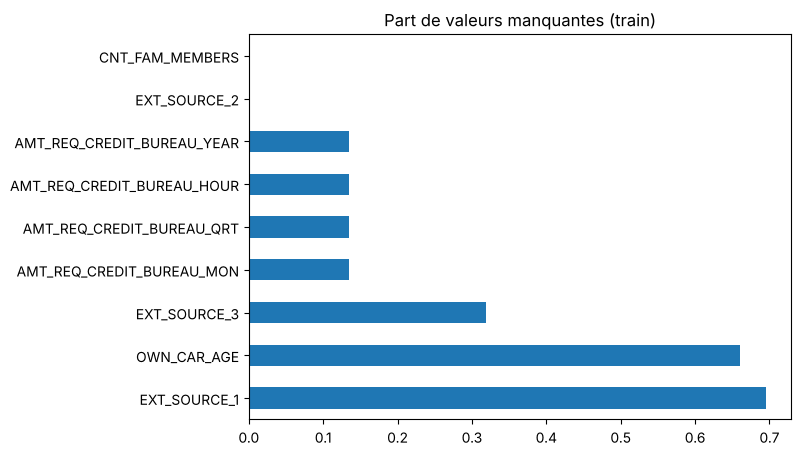

In [2]:
print('Taux de défaut :', train.TARGET.mean().round(4))
miss = train.isnull().mean().sort_values(ascending=False)
miss[miss>0].plot.barh(figsize=(7,5), title='Part de valeurs manquantes (train)'); plt.show()

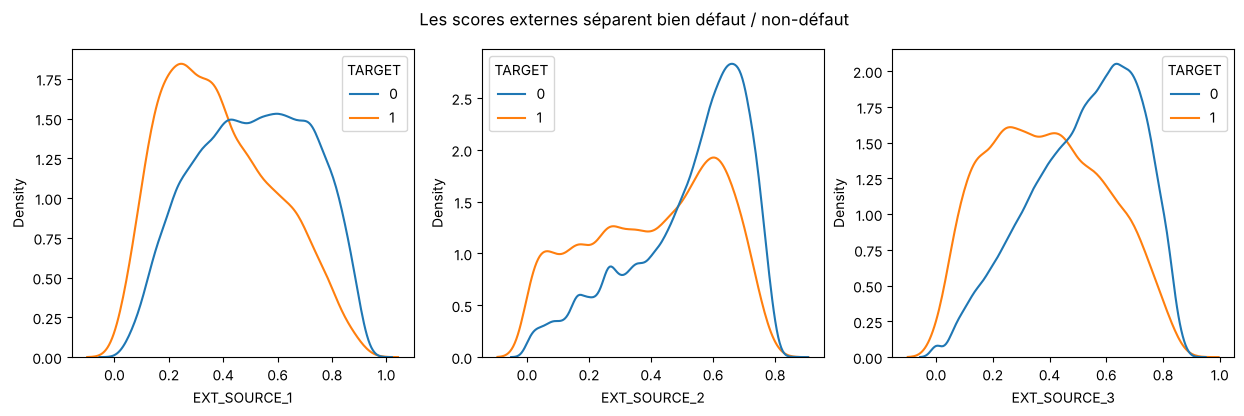

EXT_SOURCE_1    -0.154
EXT_SOURCE_2    -0.163
EXT_SOURCE_3    -0.178
DAYS_BIRTH       0.080
DAYS_EMPLOYED   -0.045
TARGET           1.000
Name: TARGET, dtype: float64


In [3]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
for a,c in zip(ax,['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']):
    sns.kdeplot(data=train, x=c, hue='TARGET', common_norm=False, ax=a)
plt.suptitle('Les scores externes séparent bien défaut / non-défaut'); plt.show()
print(train[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3','DAYS_BIRTH','DAYS_EMPLOYED','TARGET']].corr()['TARGET'].round(3))

In [4]:
print('DAYS_EMPLOYED == 365243 :', (train.DAYS_EMPLOYED==365243).sum(), '(valeur sentinelle -> NaN)')
print('OWN_CAR_AGE >= 60 :', (train.OWN_CAR_AGE>=60).sum(), '(aberrant -> NaN)')
print('ORGANIZATION_TYPE == XNA :', (train.ORGANIZATION_TYPE=='XNA').sum(), '(manquant -> NaN)')

DAYS_EMPLOYED == 365243 : 30898 (valeur sentinelle -> NaN)
OWN_CAR_AGE >= 60 : 1826 (aberrant -> NaN)
ORGANIZATION_TYPE == XNA : 30898 (manquant -> NaN)


**Constats** : classes déséquilibrées (~8 % de défauts) ; `EXT_SOURCE_*` très informatifs et en partie manquants ; valeurs sentinelles à traiter (`DAYS_EMPLOYED`=365243, `XNA`, `OWN_CAR_AGE`≥60).

## 2. Prétraitement & features

In [ ]:
y = train.TARGET.values
ids = test.SK_ID_CURR.values
df = pd.concat([train.drop(columns='TARGET'), test], keys=['tr','te']).drop(columns='SK_ID_CURR')

df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
df.loc[df.OWN_CAR_AGE>=60, 'OWN_CAR_AGE'] = np.nan
for c in ['ORGANIZATION_TYPE','CODE_GENDER']:
    df[c] = df[c].replace('XNA', np.nan)

e = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']]
df['EXT_MEAN']=e.mean(axis=1); df['EXT_MIN']=e.min(axis=1); df['EXT_MAX']=e.max(axis=1)
df['EXT_STD']=e.std(axis=1); df['EXT_PROD']=e.prod(axis=1)
df['EXT_W']=df.EXT_SOURCE_1*2+df.EXT_SOURCE_2*3+df.EXT_SOURCE_3*4
df['EXT_NAN']=e.isna().sum(axis=1)

df['CREDIT_INCOME']=df.AMT_CREDIT/df.AMT_INCOME_TOTAL
df['ANNUITY_INCOME']=df.AMT_ANNUITY/df.AMT_INCOME_TOTAL
df['CREDIT_ANNUITY']=df.AMT_CREDIT/df.AMT_ANNUITY
df['CREDIT_GOODS']=df.AMT_CREDIT/df.AMT_GOODS_PRICE
df['GOODS_INCOME']=df.AMT_GOODS_PRICE/df.AMT_INCOME_TOTAL
df['INCOME_PER_PERSON']=df.AMT_INCOME_TOTAL/df.CNT_FAM_MEMBERS
df['AGE_YEARS']=-df.DAYS_BIRTH/365
df['EMPLOYED_YEARS']=-df.DAYS_EMPLOYED/365
df['EMPLOYED_RATIO']=df.DAYS_EMPLOYED/df.DAYS_BIRTH
df['INCOME_PER_AGE']=df.AMT_INCOME_TOTAL/df.AGE_YEARS
df['PHONE_RATIO']=df.DAYS_LAST_PHONE_CHANGE/df.DAYS_BIRTH
df['REG_RATIO']=df.DAYS_REGISTRATION/df.DAYS_BIRTH
df['ID_RATIO']=df.DAYS_ID_PUBLISH/df.DAYS_BIRTH
df['CAR_EMP']=df.OWN_CAR_AGE/df.AGE_YEARS
df['CREDIT_TERM_EXT']=df.CREDIT_ANNUITY*df.EXT_MEAN
df['BUREAU_SUM']=df[[c for c in df.columns if c.startswith('AMT_REQ_')]].sum(axis=1, min_count=1)

for g,c in [('ORGANIZATION_TYPE','AMT_INCOME_TOTAL'),('OCCUPATION_TYPE','AMT_INCOME_TOTAL'),('NAME_EDUCATION_TYPE','EXT_MEAN'),('OCCUPATION_TYPE','EXT_MEAN')]:
    df[f'{c}_DIFF_{g[:4]}'] = df[c]-df.groupby(g)[c].transform('mean')

for c in [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]:
    df[c] = df[c].astype('category')
X = df.loc['tr'].reset_index(drop=True); Xt = df.loc['te'].reset_index(drop=True)
print(X.shape, Xt.shape)

(171202, 59) (61500, 59)


## 3. Modèle : LightGBM, CV stratifiée 5 plis
La moyenne des 5 modèles (un par pli) est utilisée pour le test ; l'AUC out-of-fold estime la performance finale.

In [6]:
params = dict(objective='binary', learning_rate=0.02, num_leaves=24, min_child_samples=100,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_alpha=1.0, reg_lambda=5.0,
    n_estimators=5000, random_state=SEED, n_jobs=-1, verbose=-1, cat_smooth=50, max_cat_to_onehot=8)
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof = np.zeros(len(X)); pred = np.zeros(len(Xt)); imp = pd.Series(0.0, index=X.columns)
for k,(a,b) in enumerate(skf.split(X,y)):
    m = lgb.LGBMClassifier(**params)
    m.fit(X.iloc[a], y[a], eval_set=[(X.iloc[b], y[b])], eval_metric='auc',
          callbacks=[lgb.early_stopping(200, verbose=False)])
    oof[b] = m.predict_proba(X.iloc[b])[:,1]
    pred += m.predict_proba(Xt)[:,1]/5
    imp += pd.Series(m.booster_.feature_importance('gain'), index=X.columns)/5
    print(f'Pli {k}: AUC={roc_auc_score(y[b], oof[b]):.4f}  (iter={m.best_iteration_})')
print(f'\nAUC out-of-fold : {roc_auc_score(y, oof):.4f}')

Pli 0: AUC=0.7578  (iter=992)


Pli 1: AUC=0.7626  (iter=1324)


Pli 2: AUC=0.7665  (iter=1559)


Pli 3: AUC=0.7571  (iter=1021)


Pli 4: AUC=0.7621  (iter=900)

AUC out-of-fold : 0.7612


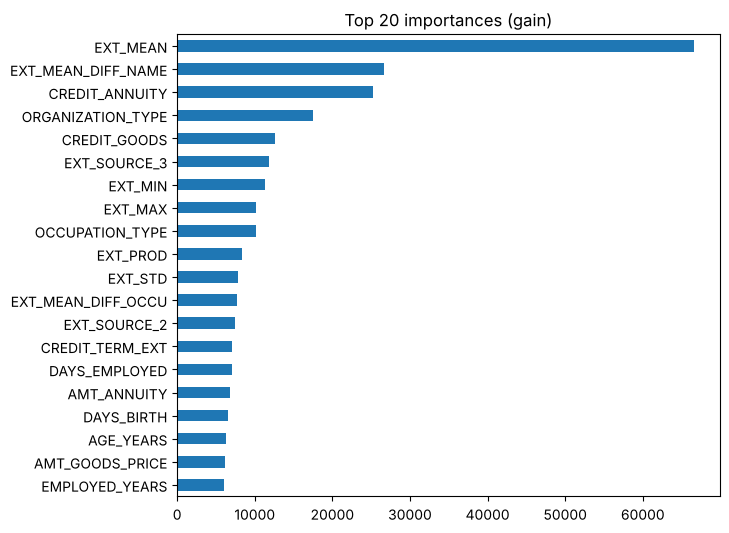

In [7]:
imp.sort_values().tail(20).plot.barh(figsize=(7,6), title='Top 20 importances (gain)'); plt.show()

**Lecture** : les `EXT_SOURCE_*` et leurs agrégats dominent ; viennent ensuite les ratios crédit/annuité/revenu et l'âge/ancienneté d'emploi, cohérents avec le risque de crédit.

## 6. Creating prediction results

In [8]:
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.030791
1,171203,0.181801
2,171204,0.149426
3,171205,0.107699
4,171206,0.209395
...,...,...
61495,232697,0.179085
61496,232698,0.033224
61497,232699,0.043112
61498,232700,0.188104


### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]

In [9]:
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)
output_file = output_dir / "submission.csv"
sample_sub.to_csv(output_file, index=False)

In [10]:
import zipfile
notebook_filename = "tutorial.ipynb"
zip_filename = "tutorial.zip"
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}'")

Successfully created: /home/claude/w/Competition/tutorial.zip
